Target names: ['Ariel Sharon' 'Colin Powell' 'Donald Rumsfeld' 'George W Bush'
 'Gerhard Schroeder' 'Hugo Chavez' 'Junichiro Koizumi' 'Tony Blair']
Number of target classes: 8
Images shape: (1348, 62, 47)


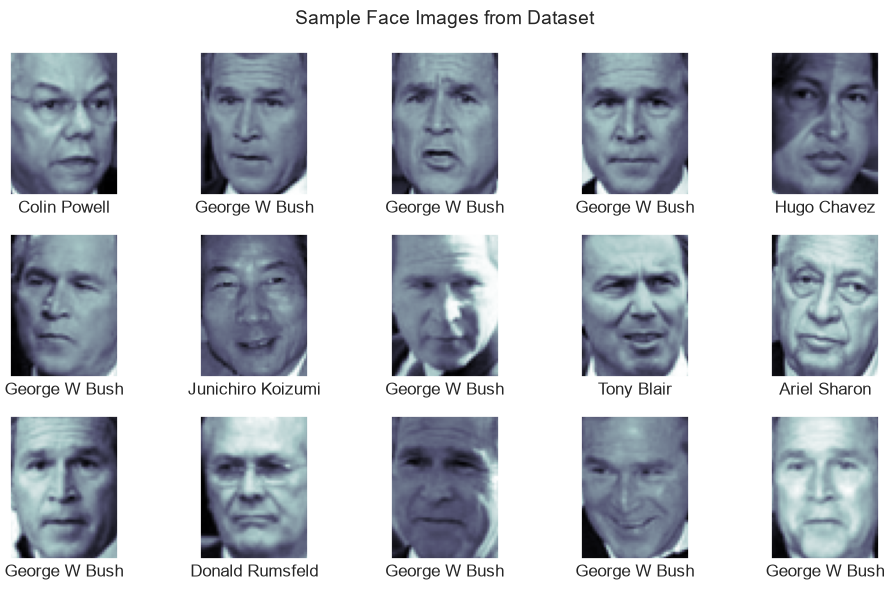

Best Parameters: {'svc__C': 5, 'svc__gamma': 0.001}
Best Cross-Validation Score: 0.828893332683022


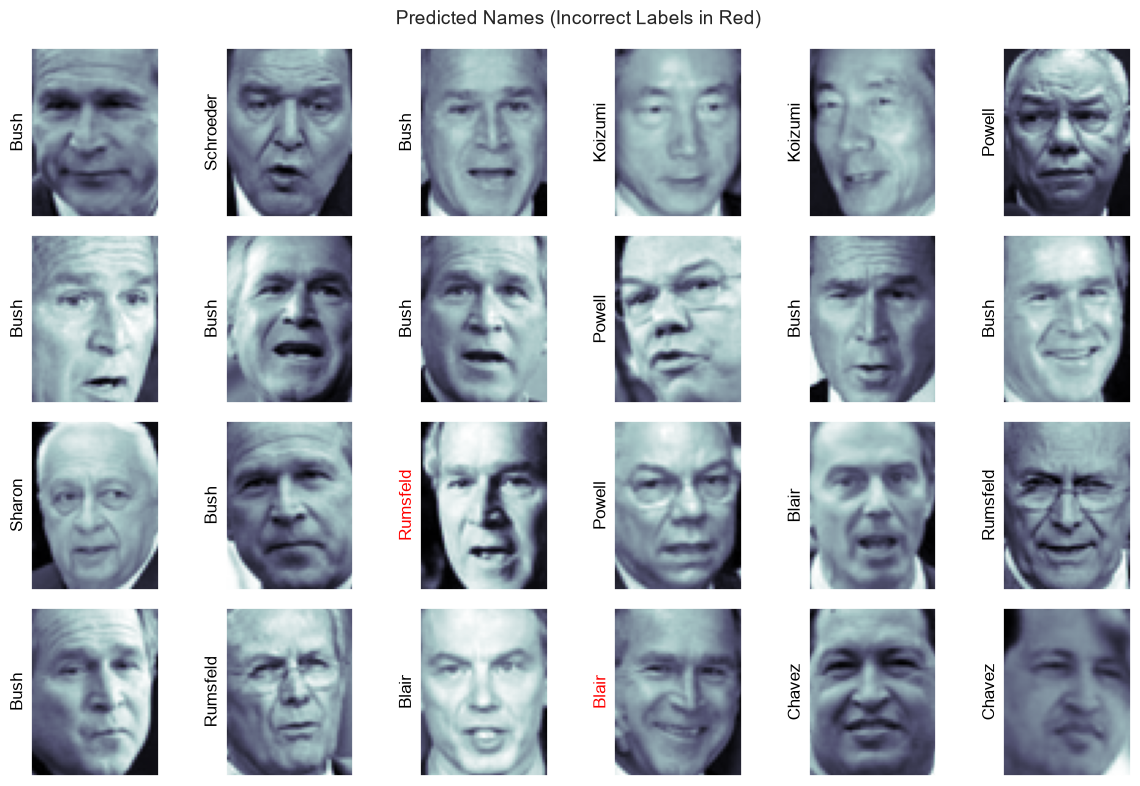


Classification Report:
                   precision    recall  f1-score   support

     Ariel Sharon       0.65      0.87      0.74        15
     Colin Powell       0.83      0.88      0.86        68
  Donald Rumsfeld       0.70      0.84      0.76        31
    George W Bush       0.97      0.80      0.88       126
Gerhard Schroeder       0.76      0.83      0.79        23
      Hugo Chavez       0.93      0.70      0.80        20
Junichiro Koizumi       0.86      1.00      0.92        12
       Tony Blair       0.82      0.98      0.89        42

         accuracy                           0.85       337
        macro avg       0.82      0.86      0.83       337
     weighted avg       0.86      0.85      0.85       337



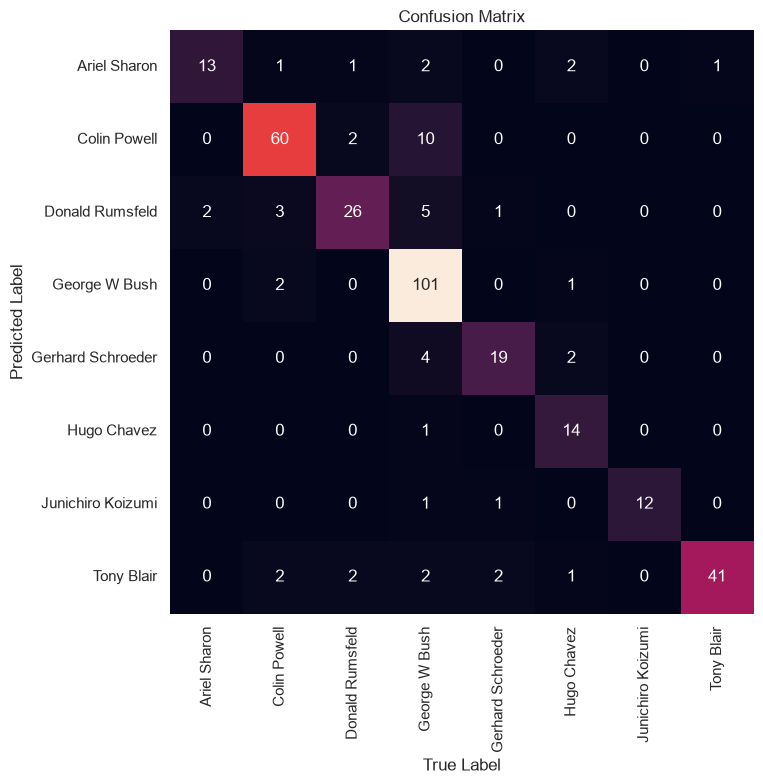

In [1]:
# ==============================================================================
# LAB: Face Image Classification using SVM and PCA (LFW Dataset)
# ==============================================================================

# --- Step 0: Import Libraries & Download Dataset ---
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_lfw_people
from sklearn.svm import SVC
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import classification_report, confusion_matrix

# Set visual style
sns.set_theme()

# Download dataset (proses ini mungkin membutuhkan waktu tergantung koneksi internet)
faces = fetch_lfw_people(min_faces_per_person=60)

print("Target names:", faces.target_names)
print("Number of target classes:", len(faces.target_names))
print("Images shape:", faces.images.shape)


# --- Step 1: Inspect Facial Images ---
fig, ax = plt.subplots(3, 5, figsize=(10, 6))
for i, axi in enumerate(ax.flat):
    axi.imshow(faces.images[i], cmap='bone')
    axi.set(xticks=[], yticks=[],
            xlabel=faces.target_names[faces.target[i]])
plt.suptitle("Sample Face Images from Dataset", size=14)
plt.tight_layout()
plt.show()


# --- Step 2: Data Preprocessing (Pipeline: PCA + SVM) ---
# Menggunakan PCA untuk reduksi dimensi ke 150 komponen utama
pca = PCA(n_components=150, whiten=True, random_state=42)
svc = SVC(kernel='rbf', class_weight='balanced')

# Membuat pipeline untuk mengeksekusi PCA dan SVC secara berurutan
model = make_pipeline(pca, svc)


# --- Step 3: Split Data ---
Xtrain, Xtest, ytrain, ytest = train_test_split(faces.data, faces.target, random_state=42)


# --- Step 4: Model Creation & Hyperparameter Tuning via GridSearchCV ---
param_grid = {
    'svc__C': [1, 5, 10, 50],
    'svc__gamma': [0.0001, 0.0005, 0.001, 0.005]
}

grid = GridSearchCV(model, param_grid)

# Gunakan cell magic %time di Jupyter Notebook/Colab untuk mencatat waktu eksekusi:
# %time grid.fit(Xtrain, ytrain)
grid.fit(Xtrain, ytrain)

print("Best Parameters:", grid.best_params_)
print("Best Cross-Validation Score:", grid.best_score_)

# Ambil model terbaik dan lakukan prediksi pada data uji
best_model = grid.best_estimator_
yfit = best_model.predict(Xtest)


# --- Step 5: Check Prediction Results ---
fig, ax = plt.subplots(4, 6, figsize=(12, 8))
for i, axi in enumerate(ax.flat):
    axi.imshow(Xtest[i].reshape(62, 47), cmap='bone')
    axi.set(xticks=[], yticks=[])
    axi.set_ylabel(faces.target_names[yfit[i]].split()[-1],
                   color='black' if yfit[i] == ytest[i] else 'red')

fig.suptitle('Predicted Names (Incorrect Labels in Red)', size=14)
plt.tight_layout()
plt.show()


# --- Step 6: Check Model Performance ---
# 1. Classification Report
print("\nClassification Report:")
print(classification_report(ytest, yfit, target_names=faces.target_names))

# 2. Confusion Matrix
plt.figure(figsize=(10, 8))
mat = confusion_matrix(ytest, yfit)
sns.heatmap(mat.T, square=True, annot=True, fmt='d', cbar=False,
            xticklabels=faces.target_names,
            yticklabels=faces.target_names)
plt.xlabel('True Label')
plt.ylabel('Predicted Label')
plt.title('Confusion Matrix')
plt.tight_layout()
plt.show()